# Priorização de contatos em telemarketing bancário
### Previsão de adesão a depósito a prazo com Aprendizado de Máquina

Projeto N3 · Aprendizado de Máquina · Prof. Fabiola Pinho Magalhães

## 1. Introdução

Um banco faz campanhas por telefone para vender depósitos a prazo. Cerca de 11 em cada 100 contatos terminam em contratação, então ligar em qualquer ordem desperdiça tempo da equipe e incomoda clientes.

**Objetivo:** estimar, antes da ligação, a chance de o cliente contratar e transformá-la em prioridade de contato.

**Quem usaria:** equipes de relacionamento e de telemarketing do banco.

**Tipo de problema:** classificação binária supervisionada. A saída útil é a probabilidade, usada para ordenar os clientes.

In [1]:
import sys
from pathlib import Path

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "dados.py").exists())
sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import roc_auc_score

from src.dados import ENTRADAS, EXCLUIDAS, carregar, dobras, separar
from src.modelos import candidatos
from src.previsao import carregar_modelo, prever
from src.treinar import executar

## 2. Dados

**Fonte:** Bank Marketing, UCI Machine Learning Repository (Moro, Rita e Cortez), licença CC BY 4.0. São contatos de um banco português entre maio de 2008 e novembro de 2010. Cada linha é um contato e `y` informa se houve contratação.

In [2]:
bruto = pd.read_csv(raiz / "dados" / "bank-additional-full.csv", sep=";")
print("Linhas e colunas:", bruto.shape)
print("Duplicatas exatas:", bruto.duplicated().sum())
print("Valores nulos:", bruto.isna().sum().sum())
desconhecidos = (bruto == "unknown").sum()
display(desconhecidos[desconhecidos > 0].rename("valores 'unknown'").to_frame())
bruto.head()

Linhas e colunas: (41188, 21)
Duplicatas exatas: 12
Valores nulos: 0


,valores 'unknown'
job,330
marital,80
education,1731
default,8597
housing,990
loan,990


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Separação antes da exploração

Separamos 20% para teste antes de analisar a relação com o alvo. A divisão é:

- **estratificada**, para manter a proporção de contratações;
- **por grupo de perfil**: como não há ID de cliente, pessoas com idade, profissão, estado civil, escolaridade e situação financeira idênticas ficam do mesmo lado. Isso reduz o risco de o mesmo cliente aparecer no treino e no teste.

In [3]:
dados = carregar()
treino, teste = separar(dados)
pd.DataFrame({"linhas": [len(treino), len(teste)],
              "taxa de adesão": [treino.alvo.mean(), teste.alvo.mean()]},
             index=["treino", "teste"]).round(4)

,linhas,taxa de adesão
treino,32940,0.1127
teste,8236,0.1127


## 4. Exploração (somente no treino)

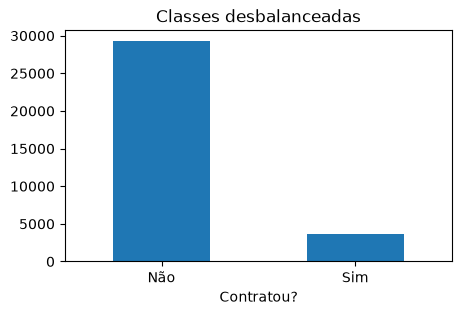

In [4]:
treino.alvo.map({0: "Não", 1: "Sim"}).value_counts().plot.bar(rot=0, figsize=(5, 3))
plt.title("Classes desbalanceadas"); plt.xlabel("Contratou?"); plt.show()

Um modelo que dissesse sempre "não" acertaria quase 89% sem encontrar nenhum cliente. Por isso **acurácia não serve** como métrica principal.

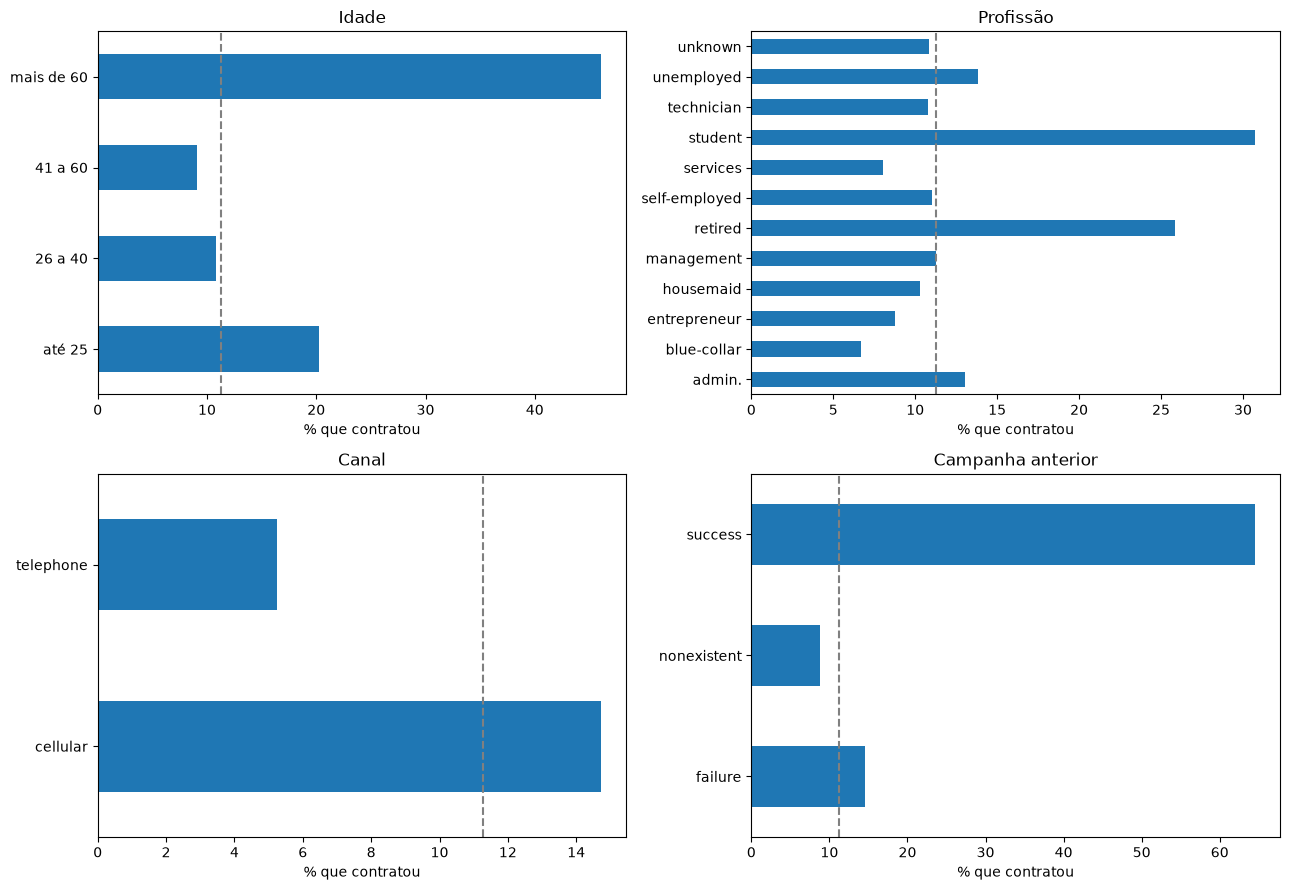

In [5]:
base = treino.assign(idade=pd.cut(treino.age, [0, 25, 40, 60, 120],
                     labels=["até 25", "26 a 40", "41 a 60", "mais de 60"]))
fig, eixos = plt.subplots(2, 2, figsize=(13, 9))
for ax, coluna, titulo in zip(eixos.flat, ["idade", "job", "contact", "poutcome"],
                              ["Idade", "Profissão", "Canal", "Campanha anterior"]):
    (100 * base.groupby(coluna, observed=True).alvo.mean()).plot.barh(ax=ax)
    ax.axvline(100 * base.alvo.mean(), color="gray", linestyle="--")
    ax.set(title=titulo, xlabel="% que contratou", ylabel="")
plt.tight_layout(); plt.show()

- Jovens e, principalmente, maiores de 60 anos aderem mais. A relação com a idade **não é linear**.
- Estudantes e aposentados se destacam, e operários aderem menos.
- Contatos por celular convertem quase três vezes mais que por telefone fixo. Parte disso pode ser efeito da época.
- Quem contratou na campanha anterior é o grupo mais forte, com cerca de 64% de adesão.

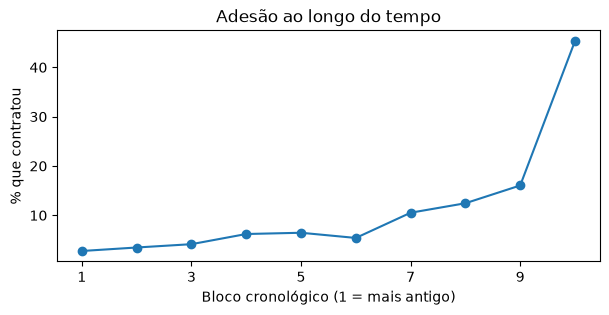

In [6]:
blocos = pd.qcut(range(len(dados)), 10, labels=range(1, 11))
em_treino = dados.index.isin(dobras(dados)[0][0])
por_epoca = dados[em_treino].groupby(blocos[em_treino], observed=True).alvo.mean()
(100 * por_epoca).plot(marker="o", figsize=(7, 3))
plt.title("Adesão ao longo do tempo"); plt.xlabel("Bloco cronológico (1 = mais antigo)")
plt.ylabel("% que contratou"); plt.show()

A taxa de adesão muda muito com o tempo, por causa do público das campanhas e da crise de 2008. Por isso há também um teste temporal na seção 8.

In [7]:
print("AUC-ROC usando apenas a duração da ligação:",
      round(roc_auc_score(treino.alvo, treino.duration), 3))

AUC-ROC usando apenas a duração da ligação: 0.818


A duração sozinha parece um ótimo modelo, mas **só é conhecida depois da ligação**. Usá-la seria vazamento de dados.

## 5. Preparação

| Tratamento | Justificativa |
|---|---|
| Remover duplicatas exatas | Não contar o mesmo registro duas vezes |
| Manter `unknown` como categoria | Não informar também carrega informação |
| Padronizar numéricas | Necessário para a Regressão Logística |
| One-hot nas categóricas | Os algoritmos precisam de números, sem inventar ordem |
| Ajustar tudo dentro do pipeline | O preparo não aprende com a validação nem com o teste |
| Manter valores extremos | São plausíveis, e modelos de árvore lidam bem com eles |
| Não balancear classes | Preservar o significado da probabilidade |

In [8]:
print("Entradas do modelo:", ENTRADAS)
pd.set_option("display.max_colwidth", None)
pd.Series(EXCLUIDAS, name="motivo da exclusão").to_frame()

Entradas do modelo: ['age', 'campaign', 'previous', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome']


,motivo da exclusão
duration,Só é conhecida depois da ligação (vazamento).
pdays,999 é um código; o histórico já é representado por poutcome e previous.
month,"Identifica a época da campanha, não o cliente."
day_of_week,"Depende de quando se liga, não de quem é o cliente."
emp.var.rate,Indicador econômico: igual para os clientes da mesma época.
cons.price.idx,Indicador econômico: igual para os clientes da mesma época.
cons.conf.idx,Indicador econômico: igual para os clientes da mesma época.
euribor3m,Indicador econômico: igual para os clientes da mesma época.
nr.employed,Indicador econômico: igual para os clientes da mesma época.


## 6. Modelagem

| Algoritmo | Ideia | Por que testar |
|---|---|---|
| Referência | Prevê sempre a taxa média | Piso de comparação |
| Regressão Logística | Soma ponderada convertida em probabilidade | Simples e interpretável |
| Árvore de Decisão | Sequência de perguntas | Capta relações não lineares |
| Random Forest | Média de muitas árvores independentes | Reduz a variância de uma árvore |
| Gradient Boosting | Cada árvore corrige os erros das anteriores | Forte em dados tabulares |

A escolha usa **validação cruzada de 5 dobras no treino**, também por grupo. A métrica de escolha é a **AUC-PR**, que resume precisão e revocação da classe rara. A AUC-ROC mede a ordenação geral, e o Brier mede o erro da probabilidade.

In [9]:
for nome, (algoritmo, grade) in candidatos().items():
    print(f"{nome}: {grade or 'sem ajuste'}")

resultado = executar()  # leva de 1 a 2 minutos
resumo = resultado["resumo"]
resultado["comparacao"].round(4)

Referência (taxa média): sem ajuste
Regressão Logística: {'modelo__C': [0.1, 1.0]}
Árvore de Decisão: {'modelo__max_depth': [4, 6]}
Random Forest: {'modelo__max_depth': [6, 10]}
Gradient Boosting: {'modelo__max_leaf_nodes': [7, 15]}


,modelo,auc_pr,desvio,auc_roc,brier,parametros
0,Gradient Boosting,0.3687,0.0140,0.7359,0.0856,"{""modelo__max_leaf_nodes"": 7}"
1,Random Forest,0.3678,0.0147,0.7353,0.0858,"{""modelo__max_depth"": 10}"
2,Regressão Logística,0.3526,0.0166,0.7291,0.0868,"{""modelo__C"": 0.1}"
3,Árvore de Decisão,0.3173,0.0129,0.7128,0.0868,"{""modelo__max_depth"": 6}"
4,Referência (taxa média),0.1127,0.0001,0.5000,0.1000,{}


O Gradient Boosting venceu pela regra definida, mas **empata na prática com a Random Forest**: a diferença é menor que o desvio entre as dobras. Os dois superam a Regressão Logística e ficam muito acima da referência.

## 7. Avaliação no teste

A prioridade alta corresponde aos 20% maiores scores das previsões fora da dobra no treino. O corte foi fixado antes de avaliar o teste.

In [10]:
pd.DataFrame({"prioridade alta": resumo["teste"],
              "corte 0,5": resumo["teste_corte_050"]}).round(3)

,prioridade alta,"corte 0,5"
contatos,8236.000,8236.000
taxa_real,0.113,0.113
probabilidade_media,0.113,0.113
auc_pr,0.369,0.369
auc_roc,0.737,0.737
brier,0.085,0.085
selecionados,0.206,0.031
precisao,0.255,0.700
revocacao,0.466,0.191
lift,2.265,6.209


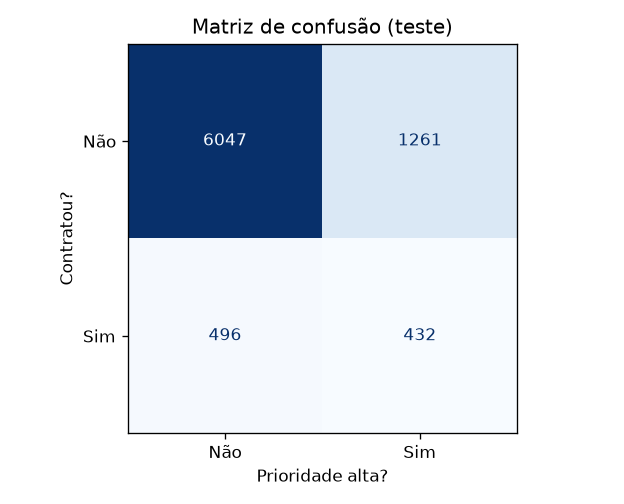

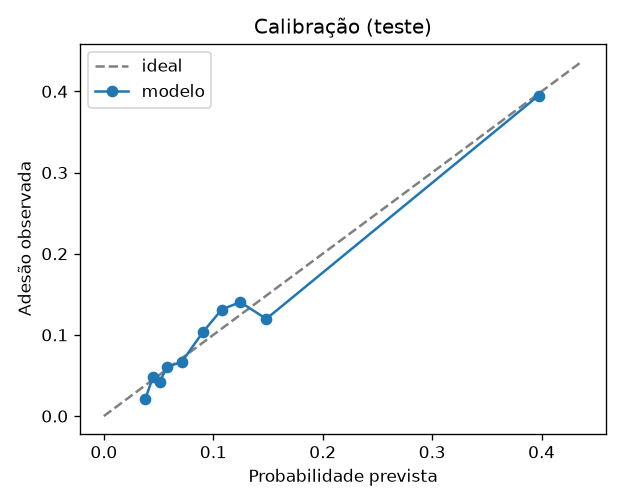

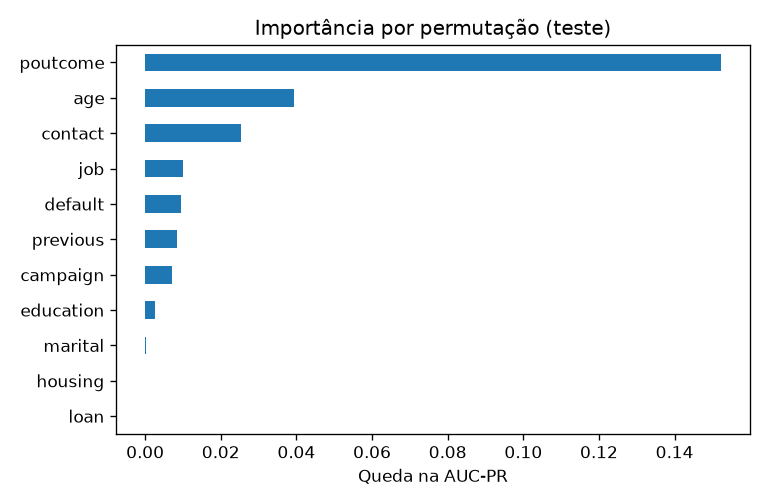

,contatos,adesao
Alta,1693.0,0.255
Média,2485.0,0.123
Baixa,4058.0,0.047


In [11]:
for nome in ["matriz_confusao", "calibracao", "importancia"]:
    display(Image(filename=str(raiz / "resultados" / "figuras" / f"{nome}.png")))
pd.DataFrame(resumo["faixas"]).T.round(3)

- Com cerca de 21% das ligações, encontramos 47% das contratações: **2,3 vezes** o resultado de ligar ao acaso.
- O corte de 0,5 acerta mais por ligação (70%), mas encontra só 19% de quem contrataria.
- A probabilidade média prevista fica muito próxima da taxa real, e as três faixas têm adesões bem separadas.

### Onde o modelo erra

**Falso positivo:** ligação priorizada que não converteu. **Falso negativo:** pessoa que contrataria e não foi priorizada.

In [12]:
resultado["erros"].round(3)

,segmento,valor,contatos,adesoes,falsos_negativos,falsos_positivos,revocacao,precisao
0,idade,26 a 40,4388,453,266,750,0.413,0.200
1,idade,41 a 60,3271,307,205,272,0.332,0.273
2,idade,até 25,408,95,24,143,0.747,0.332
3,idade,mais de 60,169,73,1,96,0.986,0.429
4,job,admin.,2022,254,115,549,0.547,0.202
5,job,blue-collar,1931,146,130,39,0.110,0.291
6,job,entrepreneur,270,20,15,25,0.250,0.167
7,job,housemaid,271,25,11,21,0.560,0.400
8,job,management,605,67,37,121,0.448,0.199
9,job,retired,352,81,21,105,0.741,0.364


- O modelo encontra só cerca de 11% dos **operários** e 11% dos contatos por **telefone fixo** que contrataram.
- Entre **maiores de 60 anos** acontece o contrário: quase todos que contratam são encontrados, mas muitos são priorizados sem contratar.
- Usado sem cuidado, o modelo deixaria alguns grupos sempre no fim da fila. O banco deveria reservar parte das ligações fora do ranking e acompanhar esses grupos.

## 8. O modelo funciona no futuro?

Treinamos nos 80% mais antigos e testamos nos 20% mais recentes, com a mesma configuração. É um teste de estresse: a configuração foi escolhida com dados de todo o período.

In [13]:
pd.Series(resumo["tempo"], name="20% mais recentes").round(3).to_frame()

,20% mais recentes
taxa_passado,0.064
contatos,8236.000
taxa_real,0.308
probabilidade_media,0.150
auc_pr,0.502
auc_roc,0.691
brier,0.216
selecionados,0.521
precisao,0.412
revocacao,0.696


A capacidade de ordenar cai um pouco (AUC-ROC de 0,74 para 0,69), mas **a probabilidade deixa de valer**: o modelo prevê cerca de 15% e a adesão real é 31%. O corte também passa a selecionar metade dos contatos. A AUC-PR sobe apenas porque há mais positivos, por isso não é comparável entre os dois períodos. Em uso real seria necessário retreinar e recalibrar.

## 9. Demonstração com uma nova entrada

A interface completa abre com `streamlit run app.py`.

In [14]:
cliente = {"age": 68, "job": "retired", "marital": "married", "education": "basic.4y",
           "default": "no", "housing": "yes", "loan": "no", "contact": "cellular",
           "campaign": 1, "previous": 1, "poutcome": "success"}
pacote = carregar_modelo()
print(prever(cliente, pacote))

try:
    prever({**cliente, "age": 999}, pacote)
except ValueError as erro:
    print("Entrada recusada:", erro)

{'probabilidade': 0.6773163319454588, 'prioridade': 'Alta', 'acao': 'Ligar primeiro.', 'vezes_a_media': 6.012072210801243, 'alertas': []}
Entrada recusada: age deve ser um inteiro de 17 a 98.


## 10. Considerações finais

É possível priorizar contatos usando só informações conhecidas antes da ligação. O modelo é moderado, não perfeito, mas mais que dobra o rendimento das primeiras ligações no período estudado.

As principais lições foram evitar vazamento, não confiar em acurácia com classes desbalanceadas, conferir se a probabilidade significa o que parece e testar no tempo.

**Limitações:** dados antigos e de um único país, ausência de ID de cliente, associação que não é causa e erros desiguais entre grupos. Idade, profissão e estado civil exigem análise ética e legal (LGPD) antes de uso real. O dataset já era conhecido do grupo por um trabalho anterior, então o teste não é totalmente inédito.

**Trabalhos futuros:** dados recentes, recalibração periódica e um experimento comparando a fila do modelo com a fila atual.

As referências estão no `README.md`.